# SAC-Based Semantic-Aware Power and Time Allocation for Hybrid NOMA-OFDMA Networks

This notebook trains and evaluates the SAC allocator, compares it with equal allocation, and saves each run in its own folder. **Run cells from top to bottom.**

**Important:** Imported CSV values are only as trustworthy as their source documentation. If no CSV is provided, the notebook labels its channel model as simulated. Semantic importance and target rates are assumptions unless included in your CSV. The semantic metric is a proxy, not a real semantic encoder/decoder.

### Required CSV columns
`distance_m` and either `channel_gain_linear` or `pathloss_db`. Optional: `x_m`, `y_m`, `semantic_importance`, `is_semantic`, `target_rate_mbps`. Use documented, compatible exports; the notebook does not automatically download or certify a research dataset.


In [10]:
%pip -q install numpy pandas matplotlib torch
import torch, numpy, pandas, matplotlib
print("Setup complete | PyTorch:", torch.__version__, "| GPU:", torch.cuda.is_available())


Setup complete | PyTorch: 2.11.0+cpu | GPU: False


In [11]:

# USER INPUTS — enter each value when prompted

U = int(input("Total number of users: "))
SEMANTIC_USERS = int(input("Number of semantic users: "))
POWER_BUDGET_CONFIG_W = float(input("Maximum power budget (W): "))

NON_SEMANTIC_USERS = U - SEMANTIC_USERS

SEM_HIGH = int(input("High-priority semantic users: "))
SEM_MEDIUM = int(input("Medium-priority semantic users: "))
SEM_LOW = int(input("Low-priority semantic users: "))

NONSEM_HIGH = int(input("High-priority non-semantic users: "))
NONSEM_MEDIUM = int(input("Medium-priority non-semantic users: "))
NONSEM_LOW = int(input("Low-priority non-semantic users: "))

assert U >= 2
assert 0 <= SEMANTIC_USERS <= U
assert POWER_BUDGET_CONFIG_W > 0
assert SEM_HIGH + SEM_MEDIUM + SEM_LOW == SEMANTIC_USERS
assert NONSEM_HIGH + NONSEM_MEDIUM + NONSEM_LOW == NON_SEMANTIC_USERS

print("Inputs validated successfully.")


Total number of users: 10
Number of semantic users: 5
Maximum power budget (W): 10
High-priority semantic users: 2
Medium-priority semantic users: 2
Low-priority semantic users: 1
High-priority non-semantic users: 2
Medium-priority non-semantic users: 2
Low-priority non-semantic users: 1
Inputs validated successfully.


In [12]:
# Results storage and restart control (works in Colab and VS Code)
from pathlib import Path
from datetime import datetime

RUN_ACTION = "NEW_RUN"
RUN_FOLDER_NAME = datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    RESULTS_ROOT = "/content/drive/MyDrive/SAC_NOMA_OFDMA_Results"
    print("Google Drive connected; saving results to Drive.")
except Exception:
    RESULTS_ROOT = str(Path.cwd() / "SAC_NOMA_OFDMA_Results")
    print("Running outside Colab; saving results in:", RESULTS_ROOT)
Path(RESULTS_ROOT).mkdir(parents=True, exist_ok=True)
print("This run will save to:", str(Path(RESULTS_ROOT) / RUN_FOLDER_NAME))


Running outside Colab; saving results in: /content/SAC_NOMA_OFDMA_Results
This run will save to: /content/SAC_NOMA_OFDMA_Results/run_20261014_174025_577187


### Optional dataset
For VS Code, place `deepmimo_channel_data.csv` or `manual_channel_data.csv` in the same folder as this notebook. Run the CSV setup cell to check whether it is found. In Colab, upload the CSV into `/content` or use the Files pane. Required columns: `distance_m` and either `channel_gain_linear` or `pathloss_db`. Other columns such as `semantic_importance`, `is_semantic`, and `target_rate_mbps` are optional.


In [13]:
# OPTIONAL CSV SETUP — VS CODE OR COLAB
# Put your CSV file in the same folder as this notebook. Accepted names:
#   deepmimo_channel_data.csv (research dataset export)
#   manual_channel_data.csv (your own CSV)
from pathlib import Path

project_folder = Path.cwd()
print("Notebook working folder:", project_folder)
found = []
for name in ("deepmimo_channel_data.csv", "manual_channel_data.csv"):
    p = project_folder / name
    if p.exists():
        found.append(str(p.resolve()))
        print("Found:", p.resolve())
if not found:
    print("No CSV found yet. Copy your CSV into the folder shown above and rerun this cell.")
    print("If you do not have a dataset, choose 'simulation' when prompted; the values will be simulated, not real measurements.")


Notebook working folder: /content
No CSV found yet. Copy your CSV into the folder shown above and rerun this cell.
If you do not have a dataset, choose 'simulation' when prompted; the values will be simulated, not real measurements.


### Main project
Run the cells from top to bottom. Enter only total users, semantic users, power budget, and semantic/non-semantic priority counts. Bandwidth and subcarriers are configured automatically by the simulation. Data source selection is automatic: research CSV if available, otherwise manual CSV, otherwise the labelled simulation model. Training/evaluation counts remain internal settings.


PyTorch: 2.11.0+cpu
Device  : cpu

CONFIGURATION
Users                 : 10
OFDMA subcarriers     : 20
Total bandwidth       : 20.00 MHz
Bandwidth/subcarrier  : 1.0000 MHz
Maximum power budget  : 10.00 W
Frame duration        : 1.0000 s

DATA PROVENANCE
Requested data mode: auto
Channel source: idealized free-space + Rayleigh simulation (not measured data)
User positions, channel fading, semantic importance, and target rates are simulated/assumed.
 User_ID Communication_Type  Semantic_Importance  Target_Rate_Mbps     X_m     Y_m  Distance_m
       1                Bit                 0.00               3.0  9.0606 56.3288     41.4257
       2           Semantic                 0.65               3.0 61.8386 38.5417     16.4756
       3           Semantic                 1.00               2.0 38.2462  1.5966     49.8100
       4                Bit                 0.00               3.0 98.3231 23.0894     55.3110
       5                Bit                 0.00               2.0 46.676

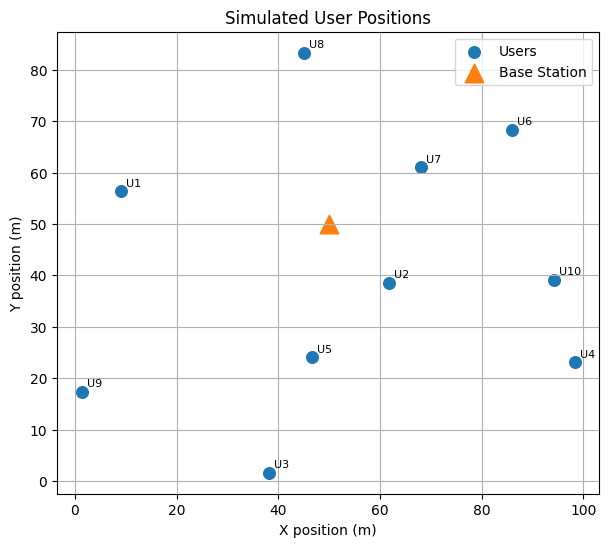

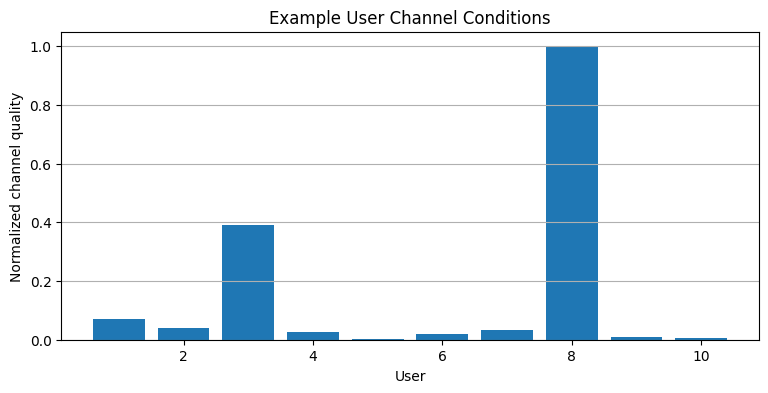

State dimension : 50
Action dimension: 21
SAC agent ready.
Episode  100 | Reward   0.9218 | Throughput  17.005 Mbps | Semantic   5.579 | QoS 0.641 | Alpha 1.0000
Episode  200 | Reward   1.1044 | Throughput  17.475 Mbps | Semantic   7.001 | QoS 0.735 | Alpha 0.9783
Episode  300 | Reward   1.1437 | Throughput  21.558 Mbps | Semantic   7.550 | QoS 0.759 | Alpha 0.9494
Episode  400 | Reward   1.0414 | Throughput  20.225 Mbps | Semantic   6.880 | QoS 0.659 | Alpha 0.9213
Episode  500 | Reward   1.0924 | Throughput  18.057 Mbps | Semantic   4.899 | QoS 0.670 | Alpha 0.8940
Episode  600 | Reward   1.1614 | Throughput  20.174 Mbps | Semantic   9.623 | QoS 0.789 | Alpha 0.8676
Episode  700 | Reward   1.1651 | Throughput  20.674 Mbps | Semantic   9.550 | QoS 0.731 | Alpha 0.8420
Episode  800 | Reward   1.0242 | Throughput  18.406 Mbps | Semantic   5.829 | QoS 0.791 | Alpha 0.8171
Episode  900 | Reward   1.0809 | Throughput  19.568 Mbps | Semantic   8.004 | QoS 0.725 | Alpha 0.7929
Episode 1000 |

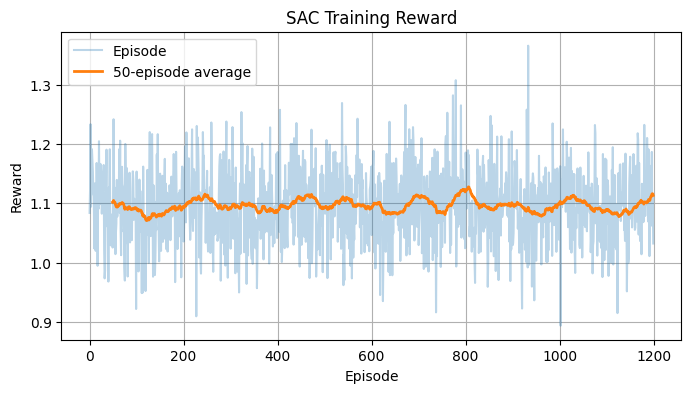

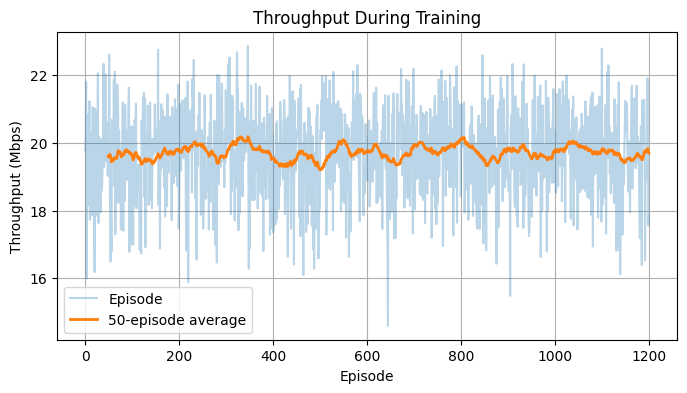

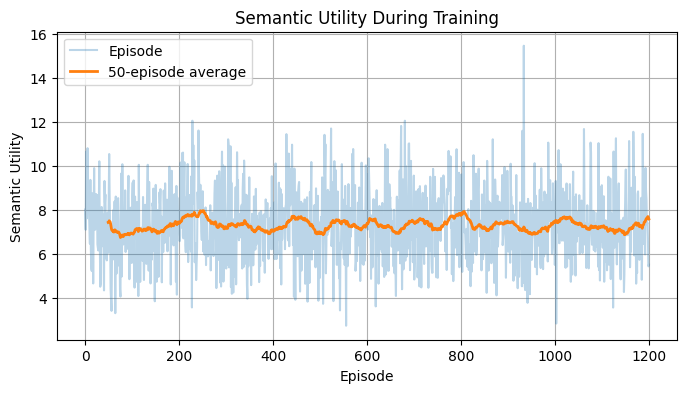

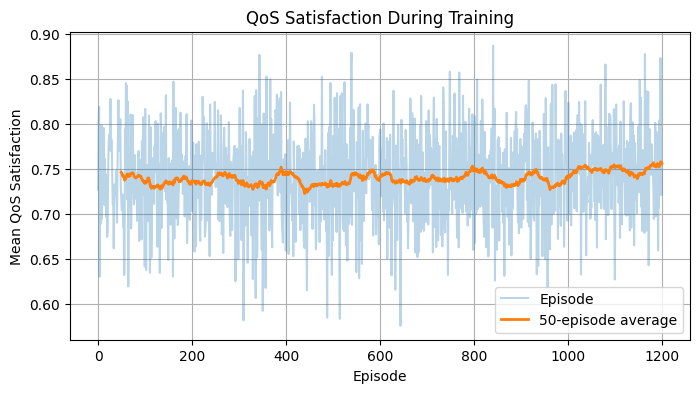


Evaluation channel source: idealized free-space + Rayleigh simulation (not measured data)
                    Metric  Equal Allocation  SAC Allocation
                    Reward            1.1670          1.1472
         Throughput (Mbps)           21.1751         20.2605
          Semantic Utility            7.7039          7.4822
          QoS Satisfaction            0.8741          0.8550
                  Fairness            0.9888          0.9884
Energy Efficiency (Mbps/W)            2.1175          3.8367
            Used Power (W)           10.0000          5.2808
FINAL SAC RESOURCE ALLOCATION — ONE NETWORK REALIZATION
 User_ID     Type  Semantic_Importance  Target_Rate_Mbps  Distance_m  Channel_Gain  Subcarrier  Power_W  Time_Allocation_s         SINR  SINR_dB  Rate_Mbps  QoS_Ratio
       1      Bit                 0.00               3.0     32.5233           0.0           2   0.5282             0.0992 5.354293e+05  57.2870    19.0303     0.6294
       2 Semantic              

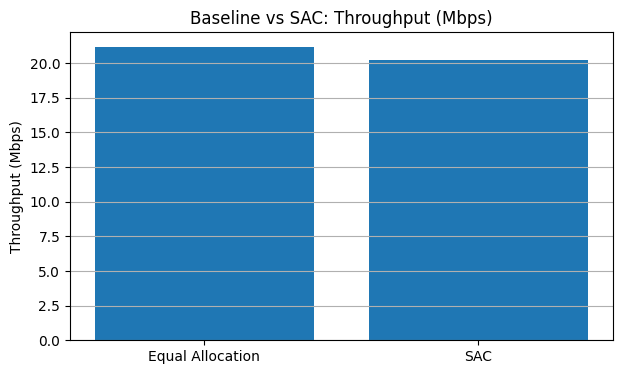

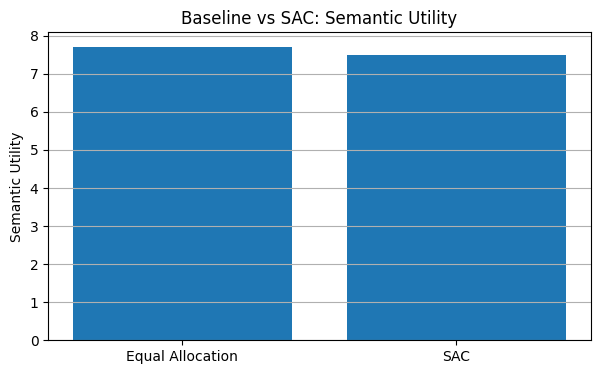

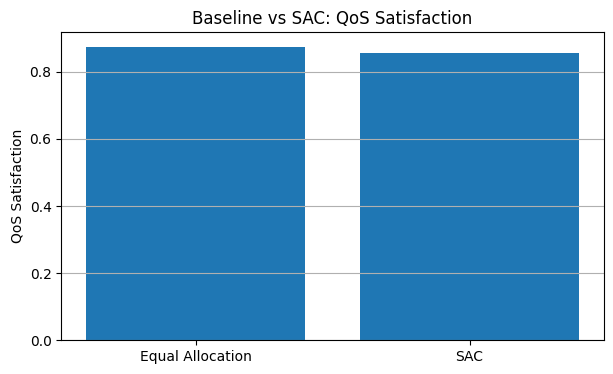

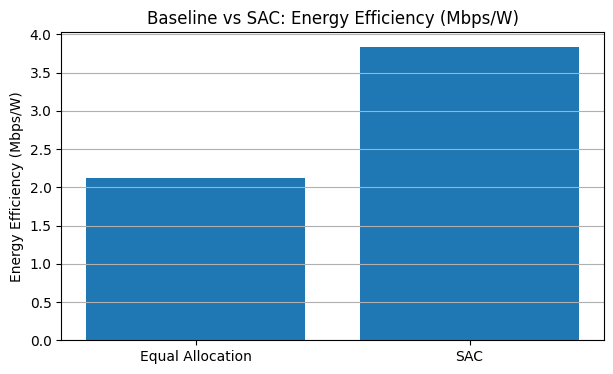

SAVED RUN OUTPUTS TO: /content/SAC_NOMA_OFDMA_Results/run_20261014_174025_577187
Files: ['comparison_summary.csv', 'equal_allocation_evaluation.csv', 'final_resource_allocation.csv', 'run_settings.json', 'sac_actor_checkpoint.pt', 'sac_evaluation.csv', 'training_history.csv', 'users_and_channel_snapshot.csv']


In [14]:
# MAIN PROJECT: train, evaluate, compare, and save results
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import random
from collections import deque
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device  :", DEVICE)

# ============================================================
# CELL 2 — CONFIGURATION FROM THE USER INPUT CELL
# ============================================================
NUM_USERS = int(U)
MAX_POWER_W = float(POWER_BUDGET_CONFIG_W)
if NUM_USERS < 2:
    raise ValueError("Total number of users must be at least 2.")
if not (0 <= SEMANTIC_USERS <= NUM_USERS):
    raise ValueError("Semantic user count must be between 0 and total users.")
if MAX_POWER_W <= 0:
    raise ValueError("Maximum power budget must be positive.")

# Automatic simulation configuration (documented heuristic, not claimed optimal).
# Increase bandwidth and subcarrier count with user count, within this model.
TOTAL_BANDWIDTH_MHZ = max(5.0, 2.0 * NUM_USERS)
NUM_SUBCARRIERS = max(4, 2 * NUM_USERS)
FRAME_TIME_S = 1.0  # fixed internal simulation setting; not asked as user input
TOTAL_BANDWIDTH_HZ = TOTAL_BANDWIDTH_MHZ * 1e6
SUBCARRIER_BW_HZ = TOTAL_BANDWIDTH_HZ / NUM_SUBCARRIERS

# Check priority counts from the input cell.
if SEM_HIGH + SEM_MEDIUM + SEM_LOW != SEMANTIC_USERS:
    raise ValueError("Semantic priority counts must add up to semantic users.")
if NONSEM_HIGH + NONSEM_MEDIUM + NONSEM_LOW != (NUM_USERS - SEMANTIC_USERS):
    raise ValueError("Non-semantic priority counts must add up to non-semantic users.")

# Physical-model parameters and provenance settings.
CARRIER_FREQUENCY_HZ = 2.4e9
NOISE_DENSITY_W_HZ = 1.380649e-23 * 290.0  # k*T at 290 K (W/Hz), before receiver noise figure
RECEIVER_NOISE_FIGURE_DB = 7.0
AREA_SIZE_M = 100.0
MIN_DISTANCE_M = 5.0
SPEED_OF_LIGHT_M_S = 299_792_458.0
# Choose data source without interactive prompts:
# "auto"     = use research CSV if present, else manual CSV, else simulation
# "research" = use deepmimo_channel_data.csv
# "manual"   = use manual_channel_data.csv (rows entered/prepared by you)
# "simulation" = always use the documented simulated channel model
DATA_MODE = "auto"  # Automatically use research CSV, then manual CSV, otherwise simulation
RESEARCH_CSV_PATH = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'deepmimo_channel_data.csv'
MANUAL_CSV_PATH = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'manual_channel_data.csv'
MAX_EPISODES = 1200  # Internal training setting; not prompted from the user
BATCH_SIZE = min(128, max(8, MAX_EPISODES // 2))
WARMUP_STEPS = min(300, max(1, MAX_EPISODES // 4))
EVAL_EPISODES = 200  # Internal evaluation setting; not prompted from the user
if MAX_EPISODES < 1 or EVAL_EPISODES < 1:
    raise ValueError("Training and evaluation episodes must be at least 1")

# Thermal noise per subcarrier, including the assumed receiver noise figure.
THERMAL_NOISE_W_HZ = NOISE_DENSITY_W_HZ * 10 ** (RECEIVER_NOISE_FIGURE_DB / 10.0)
NOISE_POWER_W = THERMAL_NOISE_W_HZ * SUBCARRIER_BW_HZ

print("\nCONFIGURATION")
print(f"Users                 : {NUM_USERS}")
print(f"OFDMA subcarriers     : {NUM_SUBCARRIERS}")
print(f"Total bandwidth       : {TOTAL_BANDWIDTH_MHZ:.2f} MHz")
print(f"Bandwidth/subcarrier  : {SUBCARRIER_BW_HZ/1e6:.4f} MHz")
print(f"Maximum power budget  : {MAX_POWER_W:.2f} W")
print(f"Frame duration        : {FRAME_TIME_S:.4f} s")

# ============================================================
# CELL 3 — DATA SOURCE, USER REQUIREMENTS, AND PROVENANCE
# ============================================================
BS_X, BS_Y = AREA_SIZE_M / 2, AREA_SIZE_M / 2

# Optional dataset CSV schema:
# Required: distance_m and exactly one of channel_gain_linear or pathloss_db.
# Optional: x_m, y_m, semantic_importance, is_semantic, target_rate_mbps.
# Export rows from a documented research source such as DeepMIMO
# (https://deepmimo.net/) and retain scenario/version/citation. DeepMIMO is a
# ray-tracing dataset, not necessarily a field-measurement dataset. A filename
# alone does not prove provenance. The fallback is not a full 3GPP TR 38.901
# implementation; that standard is available from the 3GPP specification portal.
CHANNEL_DATA = None
CHANNEL_DATA_SOURCE = "idealized free-space + Rayleigh simulation (not measured data)"


def _load_channel_csv(csv_path, source_label):
    """Load and validate a dataset/manual CSV using the documented schema."""
    candidate = pd.read_csv(csv_path)
    if "distance_m" not in candidate.columns:
        raise ValueError("CSV must contain distance_m")
    if not ({"channel_gain_linear", "pathloss_db"} & set(candidate.columns)):
        raise ValueError("CSV must contain channel_gain_linear or pathloss_db")
    candidate = candidate.replace([np.inf, -np.inf], np.nan)
    candidate = candidate.dropna(subset=["distance_m"])
    candidate = candidate[candidate["distance_m"] > 0].copy()
    if "channel_gain_linear" in candidate.columns:
        candidate = candidate.dropna(subset=["channel_gain_linear"])
        candidate = candidate[candidate["channel_gain_linear"] > 0]
    else:
        candidate = candidate.dropna(subset=["pathloss_db"])
    if len(candidate) < 1:
        raise ValueError("CSV contains no valid data rows")
    return candidate.reset_index(drop=True), f"{source_label}: {csv_path} (verify and cite its provenance)"


_mode = DATA_MODE.strip().lower()
if _mode not in {"auto", "research", "manual", "simulation"}:
    raise ValueError('DATA_MODE must be "auto", "research", "manual", or "simulation"')

if _mode == "research":
    if RESEARCH_CSV_PATH.exists():
        CHANNEL_DATA, CHANNEL_DATA_SOURCE = _load_channel_csv(RESEARCH_CSV_PATH, "Research dataset CSV")
    else:
        print(f"WARNING: Research dataset not found at {RESEARCH_CSV_PATH}; using the labelled simulation fallback.")
elif _mode == "manual":
    if MANUAL_CSV_PATH.exists():
        CHANNEL_DATA, CHANNEL_DATA_SOURCE = _load_channel_csv(MANUAL_CSV_PATH, "User-prepared/manual CSV")
    else:
        print(f"WARNING: Manual CSV not found at {MANUAL_CSV_PATH}; using the labelled simulation fallback.")
elif _mode == "auto":
    if RESEARCH_CSV_PATH.exists():
        try:
            CHANNEL_DATA, CHANNEL_DATA_SOURCE = _load_channel_csv(RESEARCH_CSV_PATH, "Research dataset CSV")
        except Exception as exc:
            print(f"WARNING: Research CSV could not be loaded ({exc}). Checking manual CSV.")
    if CHANNEL_DATA is None and MANUAL_CSV_PATH.exists():
        try:
            CHANNEL_DATA, CHANNEL_DATA_SOURCE = _load_channel_csv(MANUAL_CSV_PATH, "User-prepared/manual CSV")
        except Exception as exc:
            print(f"WARNING: Manual CSV could not be loaded ({exc}). Using the labelled simulation fallback.")

print("\nDATA PROVENANCE")
print("Requested data mode:", DATA_MODE)
print("Channel source:", CHANNEL_DATA_SOURCE)
if CHANNEL_DATA is None:
    print("User positions, channel fading, semantic importance, and target rates are simulated/assumed.")
else:
    print(f"Loaded {len(CHANNEL_DATA)} channel rows from the provided CSV.")
    missing_profile = [c for c in ("semantic_importance", "is_semantic", "target_rate_mbps") if c not in CHANNEL_DATA.columns]
    if missing_profile:
        print("Not present in dataset and therefore treated as assumptions:", ", ".join(missing_profile))


def _sample_dataset_rows(n):
    if CHANNEL_DATA is None:
        return None
    indices = np.random.choice(len(CHANNEL_DATA), size=n, replace=(len(CHANNEL_DATA) < n))
    return CHANNEL_DATA.iloc[indices].reset_index(drop=True)


INITIAL_USER_ROWS = _sample_dataset_rows(NUM_USERS)

def generate_user_profile(n):
    """Use dataset profile columns where present; otherwise use explicit assumptions."""
    rows = INITIAL_USER_ROWS if INITIAL_USER_ROWS is not None and len(INITIAL_USER_ROWS) == n else _sample_dataset_rows(n)
    if rows is not None and "semantic_importance" in rows.columns:
        importance = rows["semantic_importance"].fillna(0.0).clip(0.0, 1.0).to_numpy(dtype=float)
        is_sem = rows["is_semantic"].astype(bool).to_numpy() if "is_semantic" in rows.columns else importance > 0
    else:
        # Use the exact user counts and priority counts entered by the user.
        is_sem = np.array([True] * SEMANTIC_USERS + [False] * (n - SEMANTIC_USERS))
        np.random.shuffle(is_sem)
        sem_priorities = ([1.0] * SEM_HIGH + [0.65] * SEM_MEDIUM + [0.35] * SEM_LOW)
        nonsem_priorities = ([1.0] * NONSEM_HIGH + [0.65] * NONSEM_MEDIUM + [0.35] * NONSEM_LOW)
        sem_weights = np.array(sem_priorities, dtype=float)
        nonsem_weights = np.array(nonsem_priorities, dtype=float)
        np.random.shuffle(sem_weights)
        np.random.shuffle(nonsem_weights)
        importance = np.zeros(n, dtype=float)
        importance[is_sem] = sem_weights
    # User-selected counts and priorities are authoritative for this run.
    is_sem = np.array([True] * SEMANTIC_USERS + [False] * (n - SEMANTIC_USERS))
    np.random.shuffle(is_sem)
    sem_weights = np.array([1.0] * SEM_HIGH + [0.65] * SEM_MEDIUM + [0.35] * SEM_LOW, dtype=float)
    nonsem_weights = np.array([1.0] * NONSEM_HIGH + [0.65] * NONSEM_MEDIUM + [0.35] * NONSEM_LOW, dtype=float)
    np.random.shuffle(sem_weights)
    np.random.shuffle(nonsem_weights)
    importance = np.zeros(n, dtype=float)
    importance[is_sem] = sem_weights

    if rows is not None and "target_rate_mbps" in rows.columns:
        targets = rows["target_rate_mbps"].fillna(1.0).clip(lower=0.01).to_numpy(dtype=float)
    else:
        # Illustrative assumed demand: priority groups influence target rates.
        targets = np.empty(n, dtype=float)
        sem_targets = np.array([3.0] * SEM_HIGH + [2.0] * SEM_MEDIUM + [1.0] * SEM_LOW)
        nonsem_targets = np.array([3.0] * NONSEM_HIGH + [2.0] * NONSEM_MEDIUM + [1.0] * NONSEM_LOW)
        np.random.shuffle(sem_targets)
        np.random.shuffle(nonsem_targets)
        targets[is_sem] = sem_targets
        targets[~is_sem] = nonsem_targets
    return is_sem, importance, targets

is_semantic, semantic_importance, target_rate_mbps = generate_user_profile(NUM_USERS)

# Map positions are shown only when supplied by the dataset or generated by the model.
if INITIAL_USER_ROWS is not None:
    distance = INITIAL_USER_ROWS["distance_m"].to_numpy(dtype=float)
    if {"x_m", "y_m"}.issubset(INITIAL_USER_ROWS.columns):
        user_x = INITIAL_USER_ROWS["x_m"].to_numpy(dtype=float)
        user_y = INITIAL_USER_ROWS["y_m"].to_numpy(dtype=float)
        MAP_POSITIONS_ARE_ILLUSTRATIVE = False
    else:
        user_x = np.full(NUM_USERS, np.nan)
        user_y = np.full(NUM_USERS, np.nan)
        MAP_POSITIONS_ARE_ILLUSTRATIVE = True
else:
    user_x = np.random.uniform(0, AREA_SIZE_M, NUM_USERS)
    user_y = np.random.uniform(0, AREA_SIZE_M, NUM_USERS)
    distance = np.maximum(np.sqrt((user_x - BS_X)**2 + (user_y - BS_Y)**2), MIN_DISTANCE_M)
    MAP_POSITIONS_ARE_ILLUSTRATIVE = False

users = pd.DataFrame({
    "User_ID": np.arange(1, NUM_USERS + 1),
    "Communication_Type": np.where(is_semantic, "Semantic", "Bit"),
    "Semantic_Importance": semantic_importance,
    "Target_Rate_Mbps": target_rate_mbps,
    "X_m": user_x,
    "Y_m": user_y,
    "Distance_m": distance,
})

display(users.round(4)) if "display" in globals() else print(users.round(4).to_string(index=False))
print("\nTotal users:", NUM_USERS)

# ============================================================
# CELL 4 — CHANNEL MODEL AND HYBRID NOMA-OFDMA SCHEDULER
# ============================================================

def generate_channel():
    """Return a channel realization from a dataset or an explicitly labelled model.

    Fallback model: free-space Friis power gain times unit-mean exponential
    power fading (Rayleigh fading). It is an idealized statistical model, not
    a full 3GPP TR 38.901 implementation and not measured data.
    """
    if CHANNEL_DATA is not None:
        rows = _sample_dataset_rows(NUM_USERS)
        d = rows["distance_m"].to_numpy(dtype=float)
        if "channel_gain_linear" in rows.columns:
            gain = rows["channel_gain_linear"].to_numpy(dtype=float)
        else:
            # Convert path loss in dB to linear power gain.
            gain = 10.0 ** (-rows["pathloss_db"].to_numpy(dtype=float) / 10.0)
        if {"x_m", "y_m"}.issubset(rows.columns):
            x = rows["x_m"].to_numpy(dtype=float)
            y = rows["y_m"].to_numpy(dtype=float)
        else:
            x = np.full(NUM_USERS, np.nan)
            y = np.full(NUM_USERS, np.nan)
    else:
        # Positions and distances are simulated for each decision frame.
        x = np.random.uniform(0, AREA_SIZE_M, NUM_USERS)
        y = np.random.uniform(0, AREA_SIZE_M, NUM_USERS)
        d = np.maximum(np.sqrt((x-BS_X)**2 + (y-BS_Y)**2), MIN_DISTANCE_M)
        wavelength = SPEED_OF_LIGHT_M_S / CARRIER_FREQUENCY_HZ
        free_space_power_gain = (wavelength / (4.0 * np.pi * d)) ** 2
        rayleigh_power_fading = np.random.exponential(scale=1.0, size=NUM_USERS)
        gain = free_space_power_gain * rayleigh_power_fading

    gain = np.maximum(np.asarray(gain, dtype=float), 1e-15)
    quality = gain / max(float(np.max(gain)), 1e-30)
    return x, y, d, gain, quality


def assign_ofdma_noma(gain):
    """Hybrid scheduler: assign users to OFDMA subcarriers, then allow
    users on the same subcarrier to share it using NOMA.

    Users are sorted by channel quality and distributed across subcarriers.
    Within each subcarrier, users are ordered from weaker to stronger channel.
    This keeps the resource assignment deterministic while SAC learns power/time.
    """
    order = np.argsort(gain)  # weak -> strong
    groups = [[] for _ in range(NUM_SUBCARRIERS)]
    for i, u in enumerate(order):
        groups[i % NUM_SUBCARRIERS].append(int(u))
    return groups


def noma_sinr_for_groups(gain, power, groups):
    sinr = np.zeros(NUM_USERS, dtype=np.float64)
    for group in groups:
        # Weak-to-strong order for a simple downlink NOMA model.
        group_sorted = sorted(group, key=lambda u: gain[u])
        for pos, u in enumerate(group_sorted):
            signal = power[u] * gain[u]
            # Stronger users are treated as residual intra-cluster interference
            # for this simplified SIC model.
            interference = sum(power[v] * gain[u] for v in group_sorted[pos+1:])
            sinr[u] = signal / (interference + NOISE_POWER_W + 1e-30)
    return sinr

# Show one generated network snapshot.
x, y, d, g, q = generate_channel()
groups = assign_ofdma_noma(g)
users["Example_Channel_Gain"] = g
users["Example_Channel_Quality"] = q
users["OFDMA_Subcarrier"] = 0
for k, group in enumerate(groups):
    for u in group:
        users.loc[u, "OFDMA_Subcarrier"] = k + 1

print("Channel realization source:", CHANNEL_DATA_SOURCE)
print("OFDMA/NOMA groups for the example channel:")
for k, group in enumerate(groups, 1):
    print(f"  Subcarrier {k}: " + ", ".join(f"U{u+1}" for u in group))

# ============================================================
# CELL 5 — VISUALIZE USERS AND CHANNEL QUALITY
# ============================================================
if np.all(np.isfinite(user_x)) and np.all(np.isfinite(user_y)):
    plt.figure(figsize=(7, 6))
    plt.scatter(user_x, user_y, s=70, label="Users")
    if CHANNEL_DATA is None:
        plt.scatter(BS_X, BS_Y, marker="^", s=180, label="Base Station")
    for i in range(NUM_USERS):
        plt.text(user_x[i] + 1, user_y[i] + 1, f"U{i+1}", fontsize=8)
    plt.xlabel("X position (m)")
    plt.ylabel("Y position (m)")
    map_title = "Illustrative User Positions (not dataset coordinates)" if MAP_POSITIONS_ARE_ILLUSTRATIVE else ("Dataset User Coordinates (base-station position not provided)" if CHANNEL_DATA is not None else "Simulated User Positions")
    plt.title(map_title)
    plt.grid(True)
    plt.legend()
    plt.show()
else:
    print("Position map skipped: the supplied dataset does not contain x_m and y_m coordinates.")

plt.figure(figsize=(9, 4))
plt.bar(np.arange(NUM_USERS) + 1, q)
plt.xlabel("User")
plt.ylabel("Normalized channel quality")
plt.title("Example User Channel Conditions")
plt.grid(axis="y")
plt.show()

# ============================================================
# CELL 6 — RESOURCE EVALUATION FUNCTION
# ============================================================
def evaluate_resources(gain, groups, power, time_fraction):
    # OFDMA bandwidth is split equally across subcarriers in this model.
    bw_per_subcarrier = SUBCARRIER_BW_HZ
    user_bw = np.zeros(NUM_USERS)
    for group in groups:
        for u in group:
            user_bw[u] = bw_per_subcarrier

    sinr = noma_sinr_for_groups(gain, power, groups)
    spectral_eff = np.log2(1.0 + sinr)
    rate_bps = user_bw * spectral_eff
    rate_mbps = rate_bps / 1e6

    # Time allocation is a fraction of the frame. Effective delivered
    # information rate is weighted by the user's allocated time.
    delivered_mbits = rate_mbps * (time_fraction * FRAME_TIME_S)

    # Semantic utility proxy: important semantic users contribute more when
    # their allocated channel/time resources deliver information.
    semantic_utility = float(np.sum(
        semantic_importance * delivered_mbits
    ))

    # QoS satisfaction: fraction of target-rate demand served in the frame.
    # Compare delivered bits with target bits for the same frame duration.
    delivered_rate_mbps = rate_mbps * time_fraction
    qos_ratio = np.minimum(delivered_rate_mbps / np.maximum(target_rate_mbps, 1e-6), 1.0)
    mean_qos = float(np.mean(qos_ratio))

    total_throughput = float(np.sum(rate_mbps * time_fraction))
    used_power = float(np.sum(power))
    energy_efficiency = total_throughput / max(used_power, 1e-9)

    # Fairness of time-weighted achieved rate (Jain's fairness index).
    x = np.maximum(rate_mbps * time_fraction, 0.0)
    fairness = float((x.sum()**2) / (NUM_USERS * np.sum(x**2) + 1e-12))

    # Resource utilization penalties keep allocations inside meaningful ranges.
    power_utilization = used_power / MAX_POWER_W
    time_sum = float(np.sum(time_fraction))

    return {
        "sinr": sinr,
        "rate_mbps": rate_mbps,
        "delivered_mbits": delivered_mbits,
        "semantic_utility": semantic_utility,
        "qos_ratio": qos_ratio,
        "mean_qos": mean_qos,
        "throughput_mbps": total_throughput,
        "energy_efficiency": energy_efficiency,
        "fairness": fairness,
        "power_utilization": power_utilization,
        "time_sum": time_sum,
        "used_power": used_power,
        "user_bandwidth_hz": user_bw,
    }


def reward_from_metrics(m):
    # A transparent weighted objective. We normalize the terms to comparable
    # scales; the exact weights can be tuned for an experiment.
    throughput_score = m["throughput_mbps"] / max(NUM_USERS, 1)
    semantic_score = m["semantic_utility"] / max(NUM_USERS, 1)
    qos_score = m["mean_qos"]
    fairness_score = m["fairness"]
    energy_score = m["energy_efficiency"] / 10.0
    return float(
        0.30 * throughput_score +
        0.30 * semantic_score +
        0.15 * qos_score +
        0.15 * fairness_score +
        0.10 * energy_score
    )

# ============================================================
# CELL 7 — EQUAL-ALLOCATION BASELINE
# ============================================================
def equal_allocation(gain, groups):
    power = np.full(NUM_USERS, MAX_POWER_W / NUM_USERS, dtype=np.float64)
    time_fraction = np.full(NUM_USERS, 1.0 / NUM_USERS, dtype=np.float64)
    return power, time_fraction

# ============================================================
# CELL 8 — SAC ENVIRONMENT
# ============================================================
class HybridNOMAOFDMAEnv:
    def __init__(self):
        self.n = NUM_USERS
        self.state_dim = 5 * self.n
        self.action_dim = 2 * self.n + 1
        self.distance = None
        self.channel_gain = None
        self.channel_quality = None
        self.groups = None
        self.state = None

    def _build_state(self):
        g = self.channel_quality
        d = self.distance / (np.sqrt(2) * AREA_SIZE_M)
        s = semantic_importance
        r = target_rate_mbps / max(np.max(target_rate_mbps), 1e-9)
        sc = np.zeros(self.n, dtype=np.float32)
        for k, group in enumerate(self.groups):
            for u in group:
                sc[u] = k / max(NUM_SUBCARRIERS - 1, 1)
        return np.concatenate([g, d, s, r, sc]).astype(np.float32)

    def reset(self):
        _, _, self.distance, self.channel_gain, self.channel_quality = generate_channel()
        self.groups = assign_ofdma_noma(self.channel_gain)
        self.state = self._build_state()
        return self.state.copy()

    @staticmethod
    def _softmax_np(x):
        z = x - np.max(x)
        e = np.exp(z)
        return e / (np.sum(e) + 1e-12)

    def action_to_resources(self, action):
        action = np.asarray(action, dtype=np.float32)
        p_logits = action[:self.n]
        t_logits = action[self.n:2*self.n]
        power_fraction = self._softmax_np(p_logits)
        time_fraction = self._softmax_np(t_logits)

        # SAC decides the fraction of the available power budget to use.
        power_level = 0.05 + 0.95 * ((float(action[-1]) + 1.0) / 2.0)
        power_level = float(np.clip(power_level, 0.05, 1.0))
        total_power = power_level * MAX_POWER_W
        power = power_fraction * total_power
        return power, time_fraction, total_power

    def step(self, action):
        power, time_fraction, total_power = self.action_to_resources(action)
        metrics = evaluate_resources(self.channel_gain, self.groups, power, time_fraction)
        reward = reward_from_metrics(metrics)
        info = {**metrics, "total_power": total_power, "groups": self.groups}
        # One frame = one decision. A new episode gives a new channel realization.
        return self.state.copy(), reward, True, info


env = HybridNOMAOFDMAEnv()
state = env.reset()
print("State dimension :", env.state_dim)
print("Action dimension:", env.action_dim)

# ============================================================
# CELL 9 — REPLAY BUFFER
# ============================================================
class ReplayBuffer:
    def __init__(self, capacity=50000):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        s, a, r, ns, d = zip(*batch)
        return (
            torch.tensor(np.asarray(s), dtype=torch.float32, device=DEVICE),
            torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE),
            torch.tensor(np.asarray(r), dtype=torch.float32, device=DEVICE).unsqueeze(1),
            torch.tensor(np.asarray(ns), dtype=torch.float32, device=DEVICE),
            torch.tensor(np.asarray(d), dtype=torch.float32, device=DEVICE).unsqueeze(1),
        )

    def __len__(self):
        return len(self.buffer)

# ============================================================
# CELL 10 — SAC NETWORKS
# ============================================================
class MLP(nn.Module):
    def __init__(self, in_dim, out_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, out_dim)
        )
    def forward(self, x):
        return self.net(x)


class GaussianActor(nn.Module):
    def __init__(self, state_dim, action_dim, hidden=128):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU()
        )
        self.mu = nn.Linear(hidden, action_dim)
        self.log_std = nn.Linear(hidden, action_dim)

    def forward(self, state):
        h = self.backbone(state)
        mu = self.mu(h)
        log_std = torch.clamp(self.log_std(h), -5, 2)
        return mu, log_std

    def sample(self, state):
        mu, log_std = self(state)
        std = log_std.exp()
        dist = torch.distributions.Normal(mu, std)
        z = dist.rsample()
        action = torch.tanh(z)
        # Tanh correction for the SAC log probability.
        log_prob = dist.log_prob(z) - torch.log(1 - action.pow(2) + 1e-6)
        log_prob = log_prob.sum(dim=1, keepdim=True)
        return action, log_prob

    def deterministic(self, state):
        mu, _ = self(state)
        return torch.tanh(mu)


class Critic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden=128):
        super().__init__()
        self.q = nn.Sequential(
            nn.Linear(state_dim + action_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1)
        )
    def forward(self, state, action):
        return self.q(torch.cat([state, action], dim=1))

# ============================================================
# CELL 11 — SOFT ACTOR-CRITIC AGENT
# ============================================================
class SACAgent:
    def __init__(self, state_dim, action_dim, gamma=0.99, tau=0.005, lr=3e-4):
        self.gamma = gamma
        self.tau = tau
        self.action_dim = action_dim

        self.actor = GaussianActor(state_dim, action_dim).to(DEVICE)
        self.q1 = Critic(state_dim, action_dim).to(DEVICE)
        self.q2 = Critic(state_dim, action_dim).to(DEVICE)
        self.tq1 = Critic(state_dim, action_dim).to(DEVICE)
        self.tq2 = Critic(state_dim, action_dim).to(DEVICE)
        self.tq1.load_state_dict(self.q1.state_dict())
        self.tq2.load_state_dict(self.q2.state_dict())

        self.actor_opt = optim.Adam(self.actor.parameters(), lr=lr)
        self.q1_opt = optim.Adam(self.q1.parameters(), lr=lr)
        self.q2_opt = optim.Adam(self.q2.parameters(), lr=lr)

        self.target_entropy = -float(action_dim)
        self.log_alpha = torch.zeros(1, requires_grad=True, device=DEVICE)
        self.alpha_opt = optim.Adam([self.log_alpha], lr=lr)

    @property
    def alpha(self):
        return self.log_alpha.exp()

    def select_action(self, state, evaluate=False):
        s = torch.tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        with torch.no_grad():
            a = self.actor.deterministic(s) if evaluate else self.actor.sample(s)[0]
        return a.cpu().numpy()[0]

    def update(self, replay, batch_size):
        state, action, reward, next_state, done = replay.sample(batch_size)
        with torch.no_grad():
            next_action, next_logp = self.actor.sample(next_state)
            target_q = torch.min(self.tq1(next_state, next_action), self.tq2(next_state, next_action))
            target = reward + self.gamma * (1 - done) * (target_q - self.alpha.detach() * next_logp)

        q1_loss = F.mse_loss(self.q1(state, action), target)
        q2_loss = F.mse_loss(self.q2(state, action), target)
        self.q1_opt.zero_grad(); q1_loss.backward(); self.q1_opt.step()
        self.q2_opt.zero_grad(); q2_loss.backward(); self.q2_opt.step()

        new_action, logp = self.actor.sample(state)
        new_q = torch.min(self.q1(state, new_action), self.q2(state, new_action))
        actor_loss = (self.alpha.detach() * logp - new_q).mean()
        self.actor_opt.zero_grad(); actor_loss.backward(); self.actor_opt.step()

        alpha_loss = -(self.log_alpha * (logp + self.target_entropy).detach()).mean()
        self.alpha_opt.zero_grad(); alpha_loss.backward(); self.alpha_opt.step()

        with torch.no_grad():
            for tp, p in zip(self.tq1.parameters(), self.q1.parameters()):
                tp.mul_(1-self.tau).add_(self.tau*p)
            for tp, p in zip(self.tq2.parameters(), self.q2.parameters()):
                tp.mul_(1-self.tau).add_(self.tau*p)

        return float(actor_loss.item()), float(q1_loss.item()+q2_loss.item())

agent = SACAgent(env.state_dim, env.action_dim)
replay = ReplayBuffer()
print("SAC agent ready.")

# ============================================================
# CELL 12 — TRAIN SAC
# ============================================================
reward_history = []
throughput_history = []
semantic_history = []
qos_history = []
energy_history = []
loss_history = []

for episode in range(1, MAX_EPISODES + 1):
    state = env.reset()
    if episode <= WARMUP_STEPS:
        action = np.random.uniform(-1, 1, env.action_dim).astype(np.float32)
    else:
        action = agent.select_action(state, evaluate=False)

    next_state, reward, done, info = env.step(action)
    replay.add(state, action, reward, next_state, done)

    actor_loss = np.nan
    critic_loss = np.nan
    if len(replay) >= BATCH_SIZE:
        actor_loss, critic_loss = agent.update(replay, BATCH_SIZE)

    reward_history.append(reward)
    throughput_history.append(info["throughput_mbps"])
    semantic_history.append(info["semantic_utility"])
    qos_history.append(info["mean_qos"])
    energy_history.append(info["energy_efficiency"])
    loss_history.append(critic_loss)

    if episode % 100 == 0:
        print(
            f"Episode {episode:4d} | Reward {reward:8.4f} | "
            f"Throughput {info['throughput_mbps']:7.3f} Mbps | "
            f"Semantic {info['semantic_utility']:7.3f} | "
            f"QoS {info['mean_qos']:.3f} | Alpha {agent.alpha.item():.4f}"
        )

print("\nSAC training completed.")

# ============================================================
# CELL 13 — TRAINING CURVES
# ============================================================
def moving_average(v, w=50):
    v = np.asarray(v, dtype=float)
    if len(v) < w:
        return v
    return np.convolve(v, np.ones(w)/w, mode="valid")

figs = [
    (reward_history, "Reward", "SAC Training Reward"),
    (throughput_history, "Throughput (Mbps)", "Throughput During Training"),
    (semantic_history, "Semantic Utility", "Semantic Utility During Training"),
    (qos_history, "Mean QoS Satisfaction", "QoS Satisfaction During Training"),
]
for values, ylabel, title in figs:
    plt.figure(figsize=(8,4))
    plt.plot(values, alpha=0.3, label="Episode")
    ma = moving_average(values)
    x = np.arange(len(ma)) + (49 if len(values) >= 50 else 0)
    plt.plot(x, ma, linewidth=2, label="50-episode average")
    plt.xlabel("Episode")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.show()

# ============================================================
# CELL 14 — SAC VS EQUAL-ALLOCATION BASELINE
# ============================================================
def evaluate_agent(agent, episodes=200):
    rows = []
    for _ in range(episodes):
        state = env.reset()
        action = agent.select_action(state, evaluate=True)
        _, reward, _, info = env.step(action)
        rows.append({
            "Reward": reward,
            "Throughput_Mbps": info["throughput_mbps"],
            "Semantic_Utility": info["semantic_utility"],
            "QoS": info["mean_qos"],
            "Fairness": info["fairness"],
            "Energy_Efficiency_Mbps_per_W": info["energy_efficiency"],
            "Power_W": info["used_power"],
        })
    return pd.DataFrame(rows)

sac_eval = evaluate_agent(agent, EVAL_EPISODES)

baseline_rows = []
for _ in range(EVAL_EPISODES):
    _, _, d, gain, _ = generate_channel()
    groups = assign_ofdma_noma(gain)
    power, time_fraction = equal_allocation(gain, groups)
    m = evaluate_resources(gain, groups, power, time_fraction)
    baseline_rows.append({
        "Reward": reward_from_metrics(m),
        "Throughput_Mbps": m["throughput_mbps"],
        "Semantic_Utility": m["semantic_utility"],
        "QoS": m["mean_qos"],
        "Fairness": m["fairness"],
        "Energy_Efficiency_Mbps_per_W": m["energy_efficiency"],
        "Power_W": m["used_power"],
    })
baseline_eval = pd.DataFrame(baseline_rows)

print("\nEvaluation channel source:", CHANNEL_DATA_SOURCE)
summary = pd.DataFrame({
    "Metric": ["Reward", "Throughput (Mbps)", "Semantic Utility", "QoS Satisfaction", "Fairness", "Energy Efficiency (Mbps/W)", "Used Power (W)"],
    "Equal Allocation": baseline_eval.mean(numeric_only=True).loc[["Reward","Throughput_Mbps","Semantic_Utility","QoS","Fairness","Energy_Efficiency_Mbps_per_W","Power_W"]].values,
    "SAC Allocation": sac_eval.mean(numeric_only=True).loc[["Reward","Throughput_Mbps","Semantic_Utility","QoS","Fairness","Energy_Efficiency_Mbps_per_W","Power_W"]].values,
})
display(summary.round(4)) if "display" in globals() else print(summary.round(4).to_string(index=False))

# ============================================================
# CELL 15 — FINAL LEARNED ALLOCATION FOR ONE NETWORK SNAPSHOT
# ============================================================
state = env.reset()
action = agent.select_action(state, evaluate=True)
power, time_fraction, total_power = env.action_to_resources(action)
_, reward, _, info = env.step(action)

result = pd.DataFrame({
    "User_ID": np.arange(1, NUM_USERS+1),
    "Type": np.where(is_semantic, "Semantic", "Bit"),
    "Semantic_Importance": semantic_importance,
    "Target_Rate_Mbps": target_rate_mbps,
    "Distance_m": env.distance,
    "Channel_Gain": env.channel_gain,
    "Subcarrier": 0,
    "Power_W": power,
    "Time_Allocation_s": time_fraction * FRAME_TIME_S,
    "SINR": info["sinr"],
    "SINR_dB": 10*np.log10(np.maximum(info["sinr"], 1e-12)),
    "Rate_Mbps": info["rate_mbps"],
    "QoS_Ratio": info["qos_ratio"],
})
for k, group in enumerate(info["groups"], 1):
    for u in group:
        result.loc[u, "Subcarrier"] = k

print("FINAL SAC RESOURCE ALLOCATION — ONE NETWORK REALIZATION")
display(result.round(4)) if "display" in globals() else print(result.round(4).to_string(index=False))
print("\nTotal power used:", round(total_power, 4), "W")
print("Total allocated time:", round(np.sum(time_fraction)*FRAME_TIME_S, 4), "s")
print("Reward:", round(reward, 4))

# ============================================================
# CELL 16 — VISUAL COMPARISON
# ============================================================
metrics_to_plot = [
    ("Throughput_Mbps", "Throughput (Mbps)"),
    ("Semantic_Utility", "Semantic Utility"),
    ("QoS", "QoS Satisfaction"),
    ("Energy_Efficiency_Mbps_per_W", "Energy Efficiency (Mbps/W)"),
]
for col, label in metrics_to_plot:
    plt.figure(figsize=(7,4))
    means = [baseline_eval[col].mean(), sac_eval[col].mean()]
    plt.bar(["Equal Allocation", "SAC"], means)
    plt.ylabel(label)
    plt.title(f"Baseline vs SAC: {label}")
    plt.grid(axis="y")
    plt.show()

# ============================================================
# SAVE ALL OUTPUTS TO A UNIQUE RUN FOLDER (NEVER OVERWRITE OLD RUNS)
# ============================================================
from pathlib import Path
import json, shutil, time
OUTPUT_DIR = Path(RESULTS_ROOT) / RUN_FOLDER_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

users.to_csv(OUTPUT_DIR / "users_and_channel_snapshot.csv", index=False)
sac_eval.to_csv(OUTPUT_DIR / "sac_evaluation.csv", index=False)
baseline_eval.to_csv(OUTPUT_DIR / "equal_allocation_evaluation.csv", index=False)
summary.to_csv(OUTPUT_DIR / "comparison_summary.csv", index=False)
result.to_csv(OUTPUT_DIR / "final_resource_allocation.csv", index=False)
pd.DataFrame({
    "episode": np.arange(1, len(reward_history)+1),
    "reward": reward_history,
    "throughput_mbps": throughput_history,
    "semantic_utility": semantic_history,
    "qos_satisfaction": qos_history,
    "energy_efficiency_mbps_per_w": energy_history,
}).to_csv(OUTPUT_DIR / "training_history.csv", index=False)

# Save every currently open figure before the notebook's display objects disappear.
for fig_num in plt.get_fignums():
    fig = plt.figure(fig_num)
    fig.savefig(OUTPUT_DIR / f"figure_{fig_num:02d}.png", dpi=160, bbox_inches="tight")

settings = {
    "run_folder": RUN_FOLDER_NAME,
    "run_action": RUN_ACTION,
    "users": NUM_USERS,
    "subcarriers": NUM_SUBCARRIERS,
    "total_bandwidth_mhz": TOTAL_BANDWIDTH_MHZ,
    "max_power_w": MAX_POWER_W,
    "frame_duration_s": FRAME_TIME_S,
    "data_mode_requested": DATA_MODE,
    "data_source_used": CHANNEL_DATA_SOURCE,
    "training_episodes": MAX_EPISODES,
    "evaluation_episodes": EVAL_EPISODES,
    "note": "Simulation outputs are not measured radio data; cite any imported research dataset separately."
}
with open(OUTPUT_DIR / "run_settings.json", "w", encoding="utf-8") as f:
    json.dump(settings, f, indent=2)
torch.save(agent.actor.state_dict(), OUTPUT_DIR / "sac_actor_checkpoint.pt")
print("\
SAVED RUN OUTPUTS TO:", OUTPUT_DIR)
print("Files:", sorted(p.name for p in OUTPUT_DIR.iterdir()))
